In [2]:
import pandas as pd
import numpy as np
import seaborn as sns


In [3]:
df = pd.read_csv(r'C:\Users\HP\OneDrive\Desktop\KPMG sem3\test\HR-Attrition-V2.csv')

In [4]:
df.head()


,Employee_ID,Age,Monthly_Income,Years_at_Company,Job_Level,Overtime,Job_Satisfaction,Work_Life_Balance,Performance_Score,Distance_from_Home_km,...,Late_Days_Last_3_Months,Absence_Days_Last_Year,Commute_Time_Minutes,Employee_Engagement_Score,Manager_Rating,Internal_Transfers,Remote_Work_Days_Per_Week,Certifications,Team_Size,Attrition
0,EMP00001,55,85264.0,2.4,1,No,4,5,4.1,20,...,1,0,43.0,2.4,5.0,0,5,0,10,1
1,EMP00002,28,72037.0,2.8,2,Yes,4,2,2.7,12,...,2,3,76.0,3.4,3.8,0,0,1,16,0
2,EMP00003,22,92504.0,3.7,4,No,1,3,3.4,23,...,3,2,64.0,2.9,1.8,0,5,1,16,1
3,EMP00004,46,42949.0,2.5,1,No,5,3,3.3,21,...,4,4,58.0,2.6,3.6,0,5,2,11,1
4,EMP00005,35,25649.0,15.0,5,No,2,1,1.9,7,...,2,3,44.0,3.7,3.6,0,1,0,9,0


In [5]:
df.isnull().sum()

Employee_ID                  0
Age                          0
Monthly_Income               0
Years_at_Company             0
Job_Level                    0
Overtime                     0
Job_Satisfaction             0
Work_Life_Balance            0
Performance_Score            0
Distance_from_Home_km        0
Training_Hours_Last_Year     0
Promotions_Last_5_Years      0
Salary_Hike_Percent          0
Stock_Option                 0
Business_Travel              0
Department                   0
Education_Level              0
Job_Role                     0
Marital_Status               0
Monthly_Working_Hours        0
Projects_Handled             0
Late_Days_Last_3_Months      0
Absence_Days_Last_Year       0
Commute_Time_Minutes         0
Employee_Engagement_Score    0
Manager_Rating               0
Internal_Transfers           0
Remote_Work_Days_Per_Week    0
Certifications               0
Team_Size                    0
Attrition                    0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

# EDA


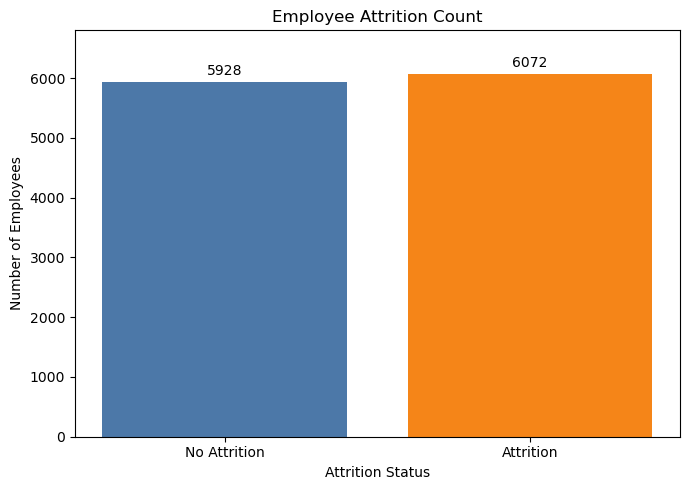

In [7]:
import matplotlib.pyplot as plt

attrition_counts = df["Attrition"].value_counts().reindex([0, 1], fill_value=0)
labels = ["No Attrition", "Attrition"]

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(labels, attrition_counts.values, color=["#4C78A8", "#F58518"])
ax.set_title("Employee Attrition Count")
ax.set_xlabel("Attrition Status")
ax.set_ylabel("Number of Employees")
ax.bar_label(bars, padding=3)
ax.set_ylim(0, max(attrition_counts.values) * 1.12)
plt.tight_layout()
plt.show()


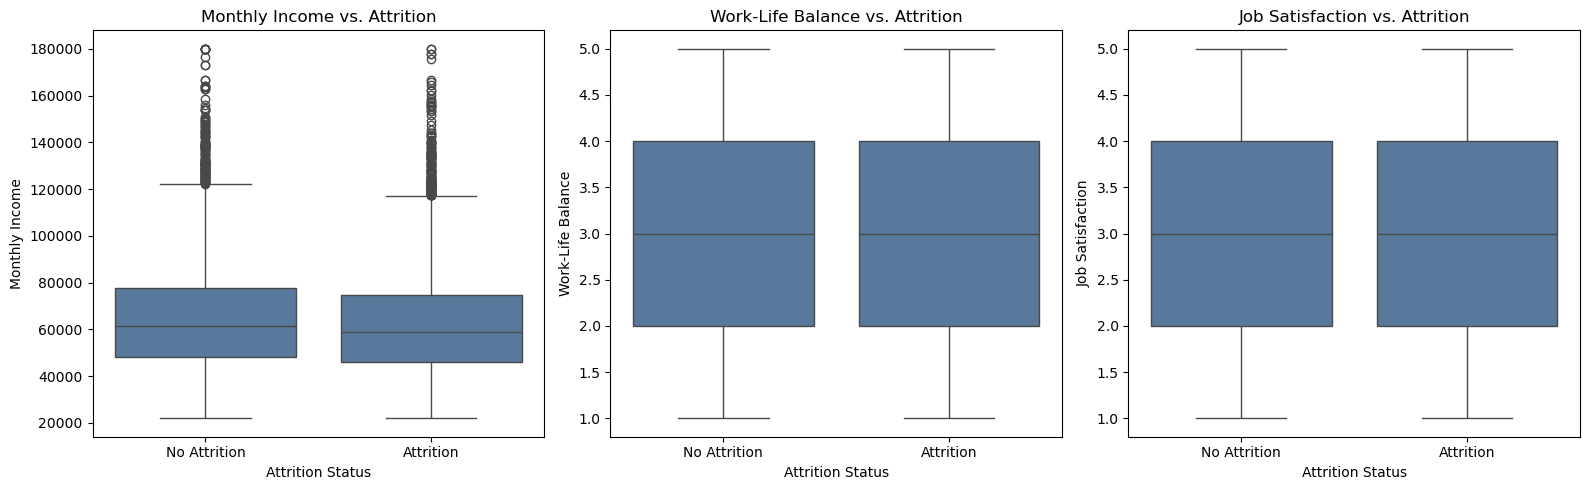

In [8]:
columns = ["Monthly_Income", "Work_Life_Balance", "Job_Satisfaction"]
titles = ["Monthly Income", "Work-Life Balance", "Job Satisfaction"]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, column, title in zip(axes, columns, titles):
    sns.boxplot(data=df, x="Attrition", y=column, ax=ax, color="#4C78A8")
    ax.set_title(f"{title} vs. Attrition")
    ax.set_xlabel("Attrition Status")
    ax.set_ylabel(title)
    ax.set_xticks([0, 1], labels=["No Attrition", "Attrition"])

plt.tight_layout()
plt.show()

In [12]:
x= df.drop(['Attrition', 'Employee_ID'], axis=1)
y=df['Attrition']

print(x.shape)
print(y.shape)

(12000, 29)
(12000,)


In [14]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [17]:
# Prepare categorical and numerical data

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
categorical_cols = x.select_dtypes(
    include=['object', 'category']
).columns.tolist()

numerical_cols = x.select_dtypes(
    include=['number']
).columns.tolist()

# Convert categories into numeric indicator columns
encoder = OneHotEncoder(handle_unknown="ignore")

# Prepare data for Decision Tree and Random Forest
preprocessor_tree = ColumnTransformer(
    [
        ('cat', encoder, categorical_cols),
        ('num', 'passthrough', numerical_cols)
    ]
)

# Prepare data for SVM, including scaling numerical variables
preprocessor_svm = ColumnTransformer(
    [
        ('cat', OneHotEncoder(handle_unknown="ignore"), categorical_cols),
        ('num', StandardScaler(), numerical_cols)
    ]
)

print('Categorical columns:', len(categorical_cols))
print('Numerical columns:', len(numerical_cols))

Categorical columns: 7
Numerical columns: 22


# Decission tree

In [19]:
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
dt_model = Pipeline(
    [
        ('preprocessor', preprocessor_tree),
        ('model', DecisionTreeClassifier(max_depth= 12, min_samples_leaf=5, class_weight='balanced', random_state=42))
    ]) 

In [21]:
dt_model.fit(x_train, y_train)
dt_predictions=dt_model.predict(x_test)


#### ACCuracy of model  decission tree

In [23]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print('Decssion tree Accuracy')
print('Accuracy:', round(accuracy_score(y_test, dt_predictions), 4))
print('classification_report')
print(classification_report(y_test, dt_predictions))

Decssion tree Accuracy
Accuracy: 0.5587
classification_report
              precision    recall  f1-score   support

           0       0.54      0.60      0.57      1164
           1       0.58      0.52      0.55      1236

    accuracy                           0.56      2400
   macro avg       0.56      0.56      0.56      2400
weighted avg       0.56      0.56      0.56      2400



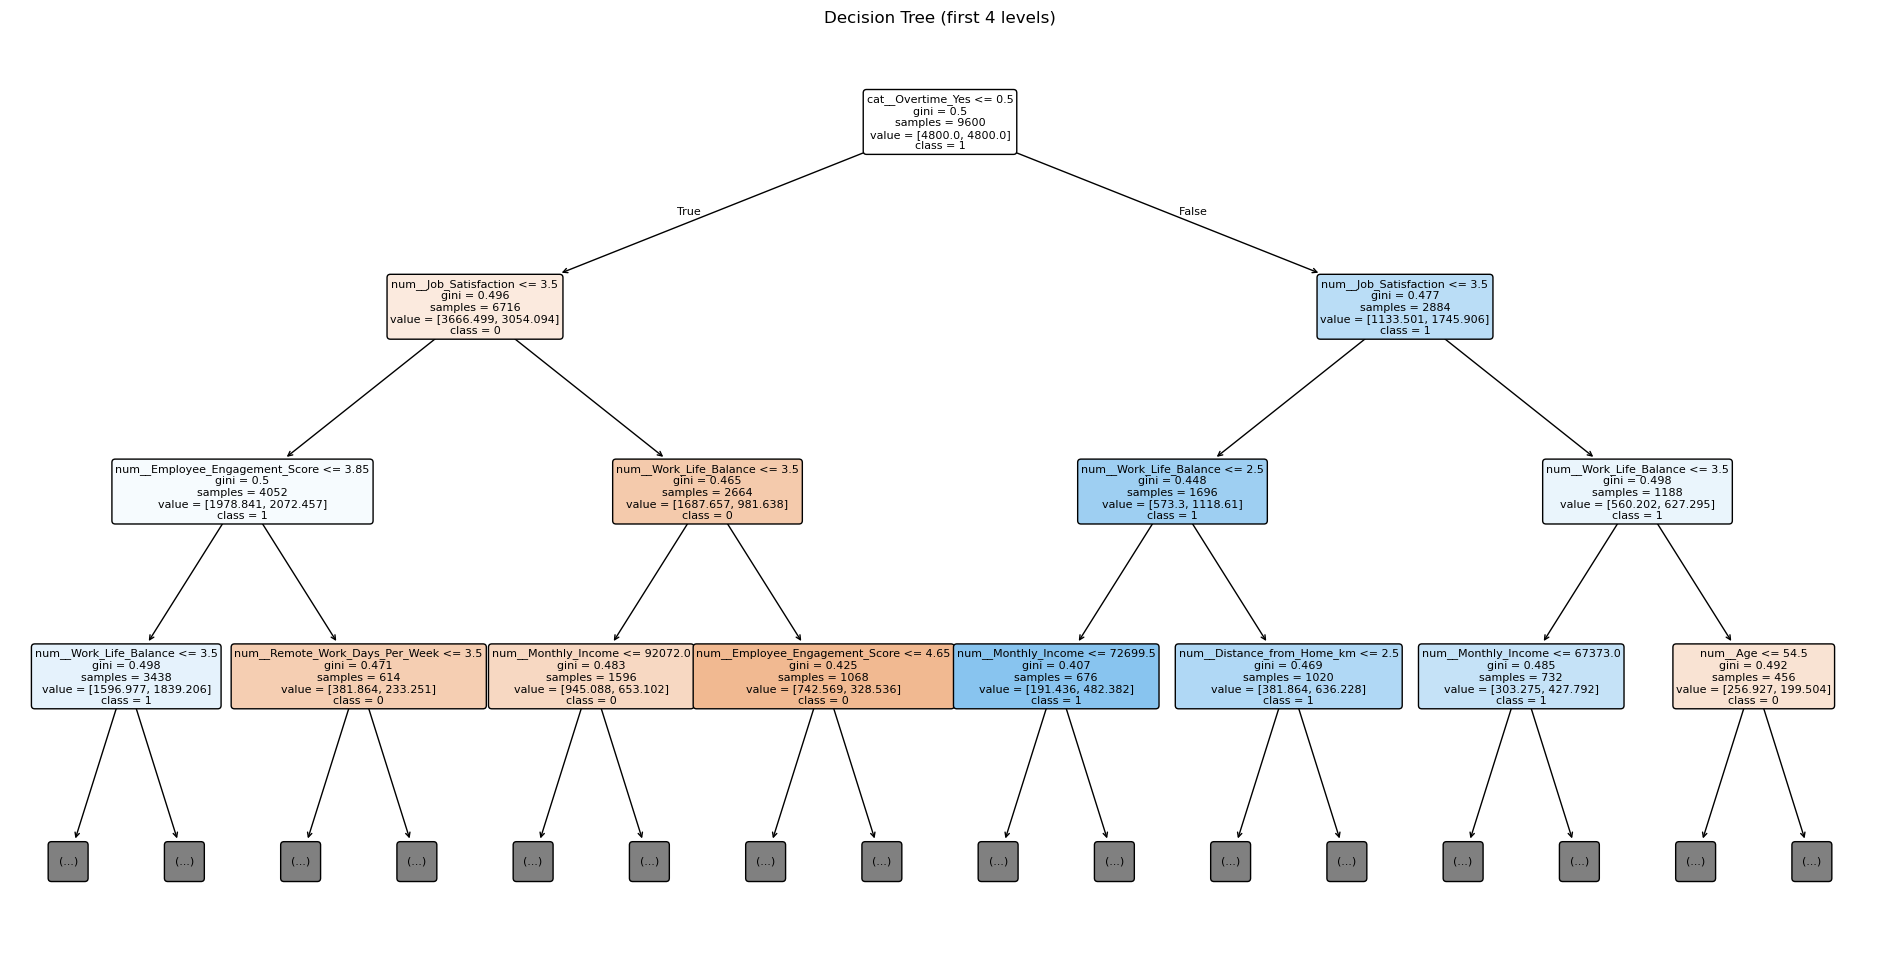

In [24]:
from sklearn.tree import plot_tree

import matplotlib.pyplot as plt

feature_names = dt_model.named_steps["preprocessor"].get_feature_names_out()
tree = dt_model.named_steps["model"]

plt.figure(figsize=(24, 12))
plot_tree(
    tree,
    feature_names=feature_names,
    class_names=tree.classes_.astype(str),
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)
plt.title("Decision Tree (first 4 levels)")
plt.show()

# Random Forest

In [26]:
from sklearn.ensemble import RandomForestClassifier
rf_model = Pipeline([
   
        ('preprocessor', preprocessor_tree),
        ('model', RandomForestClassifier(
            n_estimators=100,
             max_depth=12,
              min_samples_leaf=5, 
              class_weight='balanced', 
              random_state=42
        ))


])

In [29]:
rf_model.fit(x_train, y_train)
rf_predicted = rf_model.predict(x_test)

print("Random forest Accuracy:", round(accuracy_score(y_test, rf_predicted), 4))

print('Classification Report:', classification_report(y_test, rf_predicted))

Random forest Accuracy: 0.6162
Classification Report:               precision    recall  f1-score   support

           0       0.60      0.63      0.62      1164
           1       0.63      0.60      0.62      1236

    accuracy                           0.62      2400
   macro avg       0.62      0.62      0.62      2400
weighted avg       0.62      0.62      0.62      2400



# SVM 

In [32]:
from sklearn.svm import SVC
svm_model = Pipeline([
    ('preprocessor', preprocessor_svm),
    ('model', SVC( kernel="rbf", C=0.1, class_weight='balanced'))
])

In [34]:
svm_model.fit(x_train, y_train)
svm_predictions = svm_model.predict(x_test)

print("SVM Accuracy:", round(accuracy_score(y_test, svm_predictions), 4))
print("Classification Report:")
print(classification_report(y_test, svm_predictions))

SVM Accuracy: 0.6167
Classification Report:
              precision    recall  f1-score   support

           0       0.60      0.62      0.61      1164
           1       0.63      0.61      0.62      1236

    accuracy                           0.62      2400
   macro avg       0.62      0.62      0.62      2400
weighted avg       0.62      0.62      0.62      2400



## Poly


In [37]:
from sklearn.svm import SVC
svm_model = Pipeline([
    ('preprocessor', preprocessor_svm),
    ('model', SVC( kernel="poly", C=0.1, class_weight='balanced'))
])
svm_model.fit(x_train, y_train)
svm_predictions = svm_model.predict(x_test)

print("SVM Accuracy:", round(accuracy_score(y_test, svm_predictions), 4))
print("Classification Report:")
print(classification_report(y_test, svm_predictions))

SVM Accuracy: 0.6075
Classification Report:
              precision    recall  f1-score   support

           0       0.60      0.58      0.59      1164
           1       0.62      0.63      0.62      1236

    accuracy                           0.61      2400
   macro avg       0.61      0.61      0.61      2400
weighted avg       0.61      0.61      0.61      2400

